# VQE en el mismo Max-Cut: ansatz libre frente a QAOA

QAOA fija el ansatz (bloques de coste y mixer dictados por el annealing). VQE pregunta qué pasa si lo dejamos libre: un circuito parametrizado genérico (*hardware-efficient*) entrenado con el mismo bucle híbrido clásico-cuántico.

Referencias: handbook ([enfoque variacional](https://iraitzm.github.io/qc-handbook/es/parts/algorithms/variational.html), [VQE](https://iraitzm.github.io/qc-handbook/es/parts/algorithms/vqe.html)) y cuaderno `02-qaoa-maxcut.ipynb` de esta misma carpeta.


In [ ]:
%pip install -q qiskit qiskit-algorithms qiskit-aer qiskit-ibm-runtime qiskit-ionq dimod networkx matplotlib pylatexenc

## 1. El QUBO de partida (idéntico al de `02-qaoa-maxcut.ipynb`)

Mismo grafo de 5 nodos y 6 aristas, misma matriz Q con signo de minimización. `ExactSolver` nos da la energía de referencia contra la que compiten todos los ansatz.


In [1]:
import networkx as nx
import numpy as np
import dimod

G = nx.Graph()
G.add_edges_from([(1,2),(1,3),(2,4),(3,4),(3,5),(4,5)])
nodes = list(G.nodes)
n = len(nodes)
Q = np.zeros((n, n))
for u, v in G.edges:
    i, j = nodes.index(u), nodes.index(v)
    Q[i,i] += 1; Q[j,j] += 1; Q[i,j] -= 1; Q[j,i] -= 1
Q = -1.0 * Q  # minimización

bqm = dimod.BQM(Q, "BINARY")
optimo = float(dimod.ExactSolver().sample(bqm).first.energy)
print('Referencia exacta: E =', optimo)
print(dimod.ExactSolver().sample(bqm).truncate(4))


Referencia exacta: E = -5.0
   0  1  2  3  4 energy num_oc.
0  0  1  1  0  0   -5.0       1
1  1  0  0  1  0   -5.0       1
2  0  1  1  0  1   -5.0       1
3  1  0  0  1  1   -5.0       1
['BINARY', 4 rows, 4 samples, 5 variables]


In [2]:
lineal, cuadratico, offset = bqm.to_ising()

print('h =', dict(lineal))
print('J =', {(i, j): round(v, 3) for (i, j), v in cuadratico.items()})
print('offset =', round(offset, 3))

from qiskit.quantum_info import SparsePauliOp

# OJO convención Qiskit (little-endian): el qubit 0 es el carácter de la
# derecha, igual que en el cuaderno 02.
terminos = []
for i, h in lineal.items():
    s = ['I'] * n
    s[n - 1 - i] = 'Z'
    terminos.append((''.join(s), float(h)))
for (i, j), J in cuadratico.items():
    s = ['I'] * n
    s[n - 1 - i] = 'Z'
    s[n - 1 - j] = 'Z'
    terminos.append((''.join(s), float(J)))
H_op = SparsePauliOp.from_list(terminos)
print('Términos de Pauli:', len(terminos))


h = {0: np.float64(0.0), 1: np.float64(0.0), 2: np.float64(0.0), 3: np.float64(0.0), 4: np.float64(0.0)}
J = {(1, 0): np.float64(0.5), (2, 0): np.float64(0.5), (3, 1): np.float64(0.5), (3, 2): np.float64(0.5), (4, 2): np.float64(0.5), (4, 3): np.float64(0.5)}
offset = -3.0
Términos de Pauli: 11


## 2. La idea variacional en una línea

Para cualquier estado parametrizado $|\psi(\theta)\rangle$, el principio variacional dice que $\langle H_C \rangle_\theta \ge E_0$. VQE convierte la física en un problema de optimización: el clásico propone $\theta$, la QPU (aquí el estimador local) devuelve la energía media, y COBYLA baja por esa superficie hasta que deja de mejorar.

La diferencia con QAOA está solo en el ansatz: QAOA lo hereda del problema (coste + mixer, $2p$ parámetros), VQE usa uno genérico pensado para el hardware:

* `EfficientSU2`: capas de $R_Y$/$R_Z$ en cada qubit + entrelazadores lineales. No sabe nada del Max-Cut; lo aprende todo entrenando.
* Parámetros: $2n(\mathrm{reps}+1)$ (30 con $n=5$, reps=2, frente a 4 de QAOA con $p=2$).
* Profundidad: crece con reps, no con las aristas del grafo (QAOA paga un $R_{ZZ}$ por arista y capa).


qubits: 5 | parámetros: 30


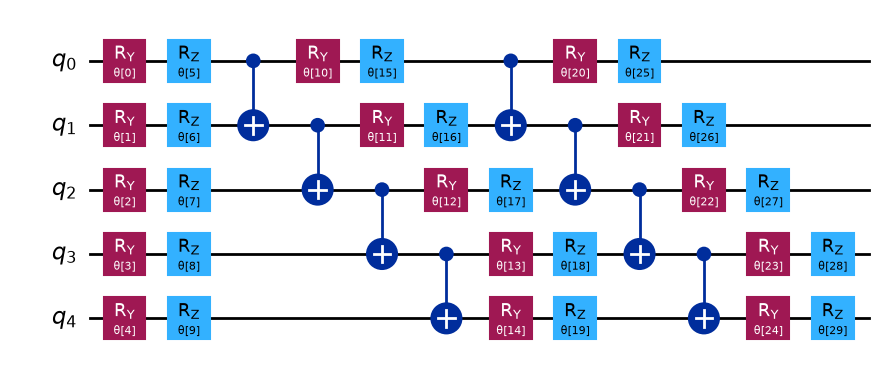

In [5]:
from qiskit.circuit.library import efficient_su2

ansatz = efficient_su2(n, reps=2, entanglement='linear')
print('qubits:', ansatz.num_qubits, '| parámetros:', ansatz.num_parameters)
ansatz.draw('mpl')


## 3. VQE optimizado con COBYLA

Mismo patrón que el QAOA del cuaderno 02, pero con estimador de energía (`StatevectorEstimator`, local y sin límite de muestras) en vez de muestreador. Punto inicial aleatorio pequeño con semilla fija: romper la simetría ayuda a COBYLA a encontrar pendiente desde la primera iteración.


VQE <H_QUBO> = -4.38 | óptimo exacto = -5.0


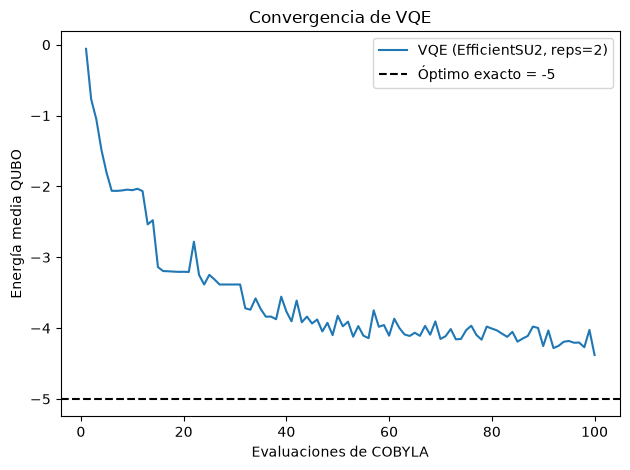

In [6]:
import matplotlib.pyplot as plt
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA
from qiskit.primitives import StatevectorEstimator

rng = np.random.default_rng(42)
punto_inicial = 0.1 * rng.standard_normal(ansatz.num_parameters)

evaluaciones, energias = [], []
def registrar(evaluacion, parametros, media, metadatos):
    evaluaciones.append(evaluacion)
    energias.append(float(media) + offset)

vqe = VQE(StatevectorEstimator(), ansatz, COBYLA(maxiter=100),
          initial_point=punto_inicial, callback=registrar)
r = vqe.compute_minimum_eigenvalue(H_op)
print('VQE <H_QUBO> =', round(float(r.optimal_value) + offset, 3), '| óptimo exacto =', optimo)

plt.plot(evaluaciones, energias, label='VQE (EfficientSU2, reps=2)')
plt.axhline(optimo, color='black', linestyle='--', label=f'Óptimo exacto = {optimo:g}')
plt.xlabel('Evaluaciones de COBYLA'); plt.ylabel('Energía media QUBO')
plt.title('Convergencia de VQE'); plt.legend(); plt.tight_layout(); plt.show()


## 4. Cara a cara: VQE frente a QAOA con el mismo presupuesto de simulación

Fijamos el mismo número de evaluaciones de COBYLA y muestreamos el circuito óptimo de cada método con Aer (2000 shots). QAOA $p=2$ tiene 4 parámetros contra 30 de VQE: la pregunta honesta es si la libertad extra compensa.


/home/iraitz/Documentos/Falcondale/Clientes/GAIA/gaia-workshop-tech/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/iraitz/Documentos/Falcondale/Clientes/GAIA/gaia-workshop-tech/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/home/iraitz/Documentos/Falcondale/Clientes/GAIA/gaia-workshop-tech/.venv/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


QAOA p=2 <H_QUBO> = -4.009 | óptimo exacto = -5.0
VQE: profundidad=13 mejor=11001 E=-5.0 shots=26
QAOA p=2: profundidad=33 mejor=10110 E=-5.0 shots=129


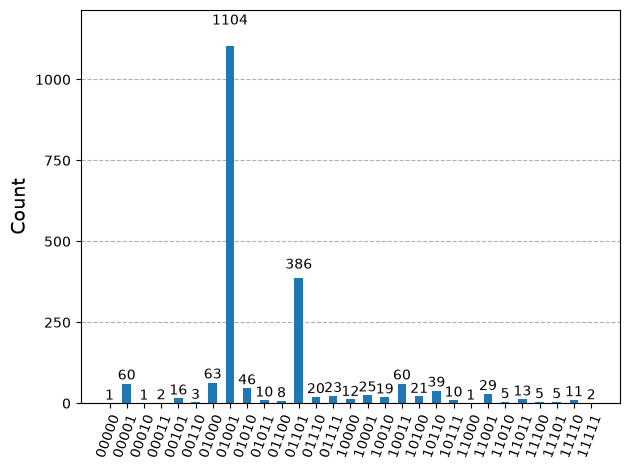

In [7]:
from qiskit_algorithms.minimum_eigensolvers import QAOA
from qiskit.primitives import StatevectorSampler
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

qaoa = QAOA(StatevectorSampler(), COBYLA(maxiter=100), reps=2)
rq = qaoa.compute_minimum_eigenvalue(H_op)
print('QAOA p=2 <H_QUBO> =', round(float(rq.optimal_value) + offset, 3), '| óptimo exacto =', optimo)

# El ansatz de QAOA es el circuito coste+mixer construido a mano en el
# cuaderno 02: lo reutilizamos ya ligado a sus parámetros óptimos.
# El ansatz de QAOA ya trae medición incluida; el de VQE no.
qc_vqe = ansatz.assign_parameters(r.optimal_point).decompose()  # Aer no entiende la caja EfficientSU2
qc_vqe.measure_all()  # el ansatz no trae bits clásicos
qc_qaoa = qaoa.ansatz.assign_parameters(rq.optimal_point).decompose(reps=5)  # abrir las cajas QAOA/coste/mixer
if qc_qaoa.num_clbits == 0:
    qc_qaoa.measure_all()

def energia(bitstr, Q):
    x = np.array([int(b) for b in bitstr[::-1]])  # qubit 0 primero
    return float(x @ Q @ x)

sim = AerSimulator()
for nombre, qc in [('VQE', qc_vqe), ('QAOA p=2', qc_qaoa)]:
    counts = sim.run(qc, shots=2000).result().get_counts(qc)
    mejor = min(counts, key=lambda s: energia(s, Q))
    print(f'{nombre}: profundidad={qc.depth()} mejor={mejor} E={energia(mejor, Q):.1f} shots={counts[mejor]}')

plot_histogram(sim.run(qc_vqe, shots=2000).result().get_counts(qc_vqe))


## 5. Envío a hardware cloud (mismo patrón que el cuaderno 02)

En clase basta Aer: cada evaluación de COBYLA sería un job en QPU (lento y con coste), así que el bucle completo en hardware se deja para `reps=1` y pocas iteraciones. Para llevar este VQE a IBM, reutilizad las celdas de envío del cuaderno 02 con dos cambios: `SamplerV2` dentro de una `Session` como muestreador y esta misma clase `VQE` con el `ansatz` de la sección 2 en lugar de `QAOA`. Con IonQ vale el mismo circuito con los parámetros óptimos ya fijados (`assign_parameters`), igual que el `qc_envio` del cuaderno 02.

In [8]:
# TODO: Copiad de las celdas anteriores a ver si podemos enviar algo a IBM o IonQ

## Para clase

- Contad parámetros y puertas de dos qubits en cada ansatz: ¿dónde paga QAOA el precio del grafo denso?
- Pregunta: con el mismo `maxiter`, ¿quién llega más cerca del óptimo, los 4 parámetros de QAOA o los 30 de VQE? ¿Y con la mitad de iteraciones?
- Degeneración $Z_2$: cada corte y su complementario empatan, esperad picos gemelos también en el histograma de VQE.
- Si COBYLA se estanca lejos del óptimo, probad otra semilla o `reps=1`: menos parámetros, superficie más fácil.
